In [1]:
import networkx as nx
import numpy as np
# from rustworkx.visualization import mpl_draw as draw_graph
import networkx as nx
from qiskit.quantum_info import SparsePauliOp
import numpy as np
import random
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler import Layout
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def count_swaps_in_QAOA_circuit(graph: nx.Graph, backend, reps=2, start='warm', swap_heuristic='basic'):
    n = graph.number_of_nodes()

    def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
        """Convert NetworkX graph to Pauli list for MaxCut."""
        pauli_list = []
        num_nodes = len(graph.nodes())
        
        for edge in graph.edges(data=True):
            u, v, data = edge
            paulis = ["I"] * num_nodes
            
            # NetworkX nodes can be any hashable type, so we use positional indices
            paulis[u] = "Z"
            paulis[v] = "Z"
            
            # Get weight with default 1.0 if not specified
            weight = data.get('weight', 1.0)
            
            # Reverse string to match RustworkX qubit ordering convention
            pauli_list.append(("".join(paulis)[::-1], float(weight)))
        
        return pauli_list
    
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)

    adj_matrix = nx.adjacency_matrix(graph).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]

    if start=='warm':
        sorted_nodes = np.argsort(fiedler)
        # for i in range(n):
        #     print(f"{sorted_nodes[i]} -> {fiedler[sorted_nodes[i]]}")

    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()

    basis_gates = backend.basis_gates
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def find_linear_chain(adj, target_length):
        def dfs(node, visited, path):
            if len(path) == target_length:
                return path
            for neighbor in adj[node]:
                if neighbor not in visited:
                    result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                    if result:
                        return result
            return None

        for start in adj:
            result = dfs(start, {start}, [start])
            if result:
                return result
        return None

    chain = find_linear_chain(adj, n)
    if not chain:
        return -1
    
    if start=='warm':
        logical_to_physical = {sorted_nodes[i]: chain[i] for i in range(n)}
    elif start=='random':
        chain_copy = chain.copy()
        random.seed(0)
        random.shuffle(chain_copy)
        logical_to_physical = {i: chain_copy[i] for i in range(n)}
    else:
        logical_to_physical = {i: chain[i] for i in range(n)}

    initial_layout = Layout({q: logical_to_physical[i] for i,q in enumerate(circuit.qubits)})

    basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)

    pm = PassManager([
        SetLayout(initial_layout),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    # return transpiled.count_ops().get("swap", 0) 

    if start=='warm':
        arr = sorted_nodes
        val = fiedler
    else:
        arr = None
        val = None
    return transpiled.count_ops().get("swap", 0), arr, val

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')
backend = service.backend('ibm_brisbane')

import networkx as nx
import matplotlib.pyplot as plt
import math

def draw_graph_custom(G, node_labels=True, edge_labels=False, layout='kamada_kawai', node_size=100, font_size=6, highlight_nodes=None):
    """
    Draws a NetworkX graph with various options.

    Parameters:
    - G: NetworkX graph
    - node_labels: Whether to show node labels
    - edge_labels: Whether to show edge weights
    - layout: Layout algorithm to use ('spring', 'circular', 'kamada_kawai', etc.)
    - node_size: Size of the nodes
    - font_size: Font size for labels
    """
    # Choose layout
    if layout == 'spring':
        pos = nx.spring_layout(G)
    elif layout == 'circular':
        pos = nx.circular_layout(G)
    elif layout == 'kamada_kawai':
        pos = nx.kamada_kawai_layout(G)
    elif layout == 'shell':
        pos = nx.shell_layout(G)
    elif layout == 'grid':
        # Create a grid layout
        n = G.number_of_nodes()
        side = math.ceil(math.sqrt(n))
        pos = {node: (i % side, -(i // side)) for i, node in enumerate(G.nodes())}
    else:
        raise ValueError(f"Unsupported layout: {layout}")
    
    if highlight_nodes is not None:
        node_colors = [
            'orange' if node in highlight_nodes else 'skyblue'
            for node in G.nodes()
        ]
    else:
        node_colors = 'skyblue'

    # Draw nodes and edges
    nx.draw(G, pos, with_labels=node_labels, node_size=node_size, font_size=font_size, edge_color='gray', node_color=node_colors)

    # Draw edge labels if requested
    if edge_labels:
        labels = nx.get_edge_attributes(G, 'weight')
        nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

    plt.title("Graph Visualization")
    plt.axis('off')
    plt.show()

import networkx as nx
import matplotlib.pyplot as plt
import random

def create_clustered_graph(num_clusters=3, cluster_size=10, intra_connect_prob=0.6, 
                           inter_edges=2, inter_path_length=1, seed=None):
    """
    Creates a graph with clusters connected by sparse inter-cluster paths of specified length.
    
    Parameters:
    - num_clusters: Number of dense clusters
    - cluster_size: Number of nodes per cluster
    - intra_connect_prob: Probability of edge creation within a cluster
    - inter_edges: Number of inter-cluster paths between any two clusters
    - inter_path_length: Length of paths between clusters (1 = direct edge, 2+ = intermediate nodes)
    - seed: Random seed for reproducibility
    
    Returns:
    - G: networkx.Graph
    """
    if seed is not None:
        random.seed(seed)
    
    G = nx.Graph()
    cluster_nodes = []
    node_offset = 0

    # Step 1: Create clusters
    for _ in range(num_clusters):
        # cluster = nx.erdos_renyi_graph(cluster_size, intra_connect_prob, seed=seed)
        # cluster = nx.connected_watts_strogatz_graph(n=cluster_size, k=2, p=0.1, seed=0)
        # cluster = nx.barabasi_albert_graph(n=cluster_size, m=1, seed=0)
        cluster = nx.random_regular_graph(d=3, n=cluster_size, seed=seed)

        mapping = {node: node + node_offset for node in cluster.nodes()}
        cluster = nx.relabel_nodes(cluster, mapping)
        G = nx.compose(G, cluster)
        cluster_nodes.append(list(mapping.values()))
        node_offset += cluster_size

    # Step 2: Connect clusters with paths of specified length
    for i in range(num_clusters):
        for j in range(i + 1, num_clusters):
            for _ in range(inter_edges):
                u = random.choice(cluster_nodes[i])
                v = random.choice(cluster_nodes[j])
                
                # Create a path of length `inter_path_length` between u and v
                prev = u
                for k in range(inter_path_length - 1):
                    intermediate = node_offset
                    G.add_node(intermediate)
                    G.add_edge(prev, intermediate)
                    prev = intermediate
                    node_offset += 1
                G.add_edge(prev, v)

    return G

import matplotlib.pyplot as plt
import networkx as nx

def gradient_graph(graph : nx.Graph, sorted, fiedler):
    fiedler_dict = {}
    n = len(graph.nodes())
    fiedler_dict = {sorted[i] : fiedler[sorted[i]] for i in range(n)}

    values = [fiedler_dict[node] for node in graph.nodes()]
    pos = nx.kamada_kawai_layout(graph)
    nx.draw(graph, pos, node_color=values, cmap=plt.cm.viridis, with_labels=True)
    # plt.colorbar(label="Fiedler Vector Value")
    plt.title("Fiedler Vector Heatmap")
    plt.show()

# gradient_graph(cluster_graph, sorted, fiedler)

import networkx as nx
import numpy as np
# from rustworkx.visualization import mpl_draw as draw_graph
import networkx as nx
from qiskit.quantum_info import SparsePauliOp
import numpy as np
import random
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler import Layout
from qiskit import transpile
from qiskit.transpiler import PassManager, CouplingMap, Layout
from qiskit.transpiler.passes import (
    SetLayout,
    EnlargeWithAncilla,
    FullAncillaAllocation,
    ApplyLayout,
    SabreSwap,
    SabreLayout
)

def count_swaps_with_SABRE(graph: nx.Graph, backend, reps=2, heuristic='basic'):
    n = graph.number_of_nodes()

    def build_max_cut_paulis(graph: nx.Graph) -> list[tuple[str, float]]:
        """Convert NetworkX graph to Pauli list for MaxCut."""
        pauli_list = []
        num_nodes = len(graph.nodes())
        
        for edge in graph.edges(data=True):
            u, v, data = edge
            paulis = ["I"] * num_nodes
            
            # NetworkX nodes can be any hashable type, so we use positional indices
            paulis[u] = "Z"
            paulis[v] = "Z"
            
            # Get weight with default 1.0 if not specified
            weight = data.get('weight', 1.0)
            
            # Reverse string to match RustworkX qubit ordering convention
            pauli_list.append(("".join(paulis)[::-1], float(weight)))
        
        return pauli_list
    
    max_cut_paulis = build_max_cut_paulis(graph)
    cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)

    circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps)
    circuit.measure_all()

    # basis_gates = backend.basis_gates
    basis_gates={'cx', 'sx', 'id', 'rz', 'x'}
    coupling_map = backend.coupling_map

    basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)

    pm = PassManager([
        # SetLayout(initial_layout),
        SabreLayout(coupling_map, skip_routing=True, seed=0),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        SabreSwap(coupling_map, heuristic=heuristic, seed=0)
    ])

    # Transpile using the custom pipeline
    transpiled = pm.run(basis_change)
    return transpiled.count_ops().get("swap", 0) 

    # if start=='warm':
    #     arr = sorted_nodes
    #     val = fiedler
    # else:
    #     arr = None
    #     val = None
    # return transpiled.count_ops().get("swap", 0), arr, val

    from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RXGate, RZZGate
import networkx as nx

def count_swaps_in_ordered_circuit(graph: nx.Graph, backend, reps=2, start='warm', swap_heuristic='basic'):
    n = graph.number_of_nodes()
    adj_matrix = nx.adjacency_matrix(graph).todense()
    L = laplacian(adj_matrix)
    vals, vecs = eigh(L)
    fiedler = vecs[:,1]

    sorted_nodes = np.argsort(fiedler)

    basis_gates={'cx', 'sx', 'id', 'rz', 'x'}
    coupling_map = backend.coupling_map

    # adjacency as a dict: {qubit: [connected_qubits]}
    adj = {i: [] for i in range(backend.configuration().num_qubits)}
    for (i, j) in coupling_map:
        adj[i].append(j)
        adj[j].append(i)

    def find_linear_chain(adj, target_length):
        def dfs(node, visited, path):
            if len(path) == target_length:
                return path
            for neighbor in adj[node]:
                if neighbor not in visited:
                    result = dfs(neighbor, visited | {neighbor}, path + [neighbor])
                    if result:
                        return result
            return None

        for start in adj:
            result = dfs(start, {start}, [start])
            if result:
                return result
        return None

    chain = find_linear_chain(adj, n)

    logical_to_physical = {}

    logical_to_physical['warm'] = {sorted_nodes[i]: chain[i] for i in range(n)}

    chain_copy = chain.copy()
    random.seed(0)
    random.shuffle(chain_copy)
    logical_to_physical['random'] = {i: chain_copy[i] for i in range(n)}

    logical_to_physical['cold'] = {i: chain[i] for i in range(n)}

    def custom_qaoa_ansatz(cost_graph: nx.Graph, layout: dict, coupling_map: list[tuple[int, int]], reps: int) -> QuantumCircuit:
        num_qubits = len(cost_graph.nodes)
        circuit = QuantumCircuit(num_qubits)

        # Parameters
        gammas = ParameterVector('γ', reps)
        betas = ParameterVector('β', reps)

        # Hadamard initialization
        circuit.h(range(num_qubits))

        # Coupling graph for distance calculation
        coupling_graph = nx.Graph()
        coupling_graph.add_edges_from(coupling_map)

        def physical_distance(q1, q2):
            try:
                return nx.shortest_path_length(coupling_graph, q1, q2)
            except nx.NetworkXNoPath:
                return float('inf')

        # Precompute sorted edges (by physical adjacency/distance)
        edge_info = []
        for i, j in cost_graph.edges():
            p_i = layout[i]
            p_j = layout[j]
            dist = physical_distance(p_i, p_j)
            edge_info.append((i, j, dist))
        edge_info.sort(key=lambda x: x[2])

        # Build QAOA layers
        for rep in range(reps):
            # Cost Layer
            for i, j, _ in edge_info:
                circuit.append(RZZGate(gammas[rep]), [i, j])
            circuit.barrier()

            # Mixer Layer (RX(2*β))
            for q in range(num_qubits):
                circuit.rx(2 * betas[rep], q)
            circuit.barrier()
        circuit.measure_all()

        return circuit

    circuit = custom_qaoa_ansatz(graph, logical_to_physical[start], coupling_map, 2)

    layouts = {}

    layouts['warm'] = Layout({q: logical_to_physical['warm'][i] for i,q in enumerate(circuit.qubits)})
    layouts['random'] = Layout({q: logical_to_physical['random'][i] for i,q in enumerate(circuit.qubits)})
    layouts['cold'] = Layout({q: logical_to_physical['cold'][i] for i,q in enumerate(circuit.qubits)})

    pm = PassManager([
        SetLayout(layouts[start]),
        EnlargeWithAncilla(),
        FullAncillaAllocation(coupling_map),
        ApplyLayout(),
        # LayoutTransformation(),
        # Commuting2qGateRouter(),
        SabreSwap(coupling_map, heuristic=swap_heuristic, seed=0),
        # BasicSwap(coupling_map)
    ])

    # Transpile using the custom pipeline
    # transpiled = pm.run(decomp)
    basis_change = transpile(circuit, basis_gates=basis_gates, seed_transpiler=0)
    transpiled = pm.run(basis_change)
    # transpiled.draw('mpl', fold=False)
    return transpiled.count_ops().get('swap', 0)

import networkx as nx
import numpy as np
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import laplacian

def random_spanning_tree_laplacian(G):
    """Sample a uniform random spanning tree and return its Laplacian."""
    T = nx.random_spanning_tree(G, seed=np.random.randint(1e6))
    T = T.to_undirected()  # Ensure undirected
    L = laplacian(nx.to_scipy_sparse_array(T, dtype=float), normed=False)
    return L

def average_tree_laplacians(G, num_samples=20):
    """Average Laplacians of random spanning trees to build a spectral sparsifier."""
    n = G.number_of_nodes()
    avg_L = np.zeros((n, n))

    for _ in range(num_samples):
        L_tree = random_spanning_tree_laplacian(G)
        avg_L += L_tree.toarray()  # accumulate
    
    avg_L /= num_samples
    return avg_L

def laplacian_to_graph(L):
    """Convert a Laplacian matrix back to a weighted NetworkX graph."""
    n = L.shape[0]
    G = nx.Graph()
    for i in range(n):
        for j in range(i + 1, n):
            w = -L[i, j]
            if w > 0:
                G.add_edge(i, j, weight=w)
    return G

def binarize_weighted_graph(G_weighted, k=None, threshold=None):
    """
    Convert a weighted graph to an unweighted one by keeping top-k or thresholded edges.
    
    Args:
        G_weighted: weighted NetworkX graph
        k: number of edges to retain (keep top-k weighted)
        threshold: retain edges with weight >= threshold

    Returns:
        NetworkX unweighted graph
    """
    edges = list(G_weighted.edges(data=True))
    if k is not None:
        # Sort by descending edge weight and keep top-k
        edges = sorted(edges, key=lambda x: x[2]['weight'], reverse=True)[:k]
    elif threshold is not None:
        # Keep only edges with weight above threshold
        edges = [e for e in edges if e[2]['weight'] >= threshold]
    else:
        raise ValueError("Specify either k or threshold.")

    G_unweighted = nx.Graph()
    G_unweighted.add_nodes_from(G_weighted.nodes())
    G_unweighted.add_edges_from((u, v) for u, v, _ in edges)
    return G_unweighted

graph = create_clustered_graph(num_clusters=2, cluster_size=48, intra_connect_prob=0.15, inter_edges=1, inter_path_length=3, seed=0)
# draw_graph_custom(graph)

from math import log, ceil
# Generate spectral sparsifier
avg_L = average_tree_laplacians(graph, num_samples=ceil(log(graph.number_of_nodes())/(0.4**2)))

# Convert back to a graph
G_sparsified = laplacian_to_graph(avg_L)

# Show edge count reduction
print(f"Original edges: {graph.number_of_edges()}")
print(f"Sparsified edges: {G_sparsified.number_of_edges()}")
# draw_graph_custom(G_sparsified)

# tree = nx.minimum_spanning_tree(G_sparsified, weight='weight')
# tree = nx.maximum_spanning_tree(G_sparsified, weight='weight')
lamo = nx.random_spanning_tree(G_sparsified)
# draw_graph_custom(lamo)

def remove_edge_weights(G):
    """Returns a copy of G with all edges unweighted (i.e., removes the 'weight' attribute)."""
    G_unweighted = nx.Graph()
    G_unweighted.add_nodes_from(G.nodes())

    # Add edges without weight attributes
    G_unweighted.add_edges_from((u, v) for u, v in G.edges())

    return G_unweighted

lmao = remove_edge_weights(lamo)
# draw_graph_custom(lmao)


C:\Users\devra\AppData\Local\Temp\ipykernel_2964\528977515.py:129: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud" and "local" will be the only valid channels. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel='ibm_quantum', token='205d1b23f51dba2efe445b1b44f1e07939499dba4f4343c67d9004c25b833489b950240921dc782935c419c08569dbc6d642584e5835a97fde387586b542d8ac')


Original edges: 147
Sparsified edges: 1591


KeyboardInterrupt: 

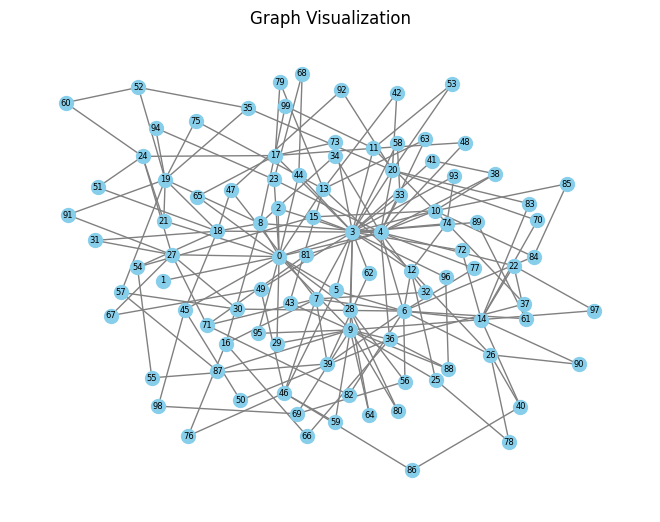

In [6]:
graph = nx.barabasi_albert_graph(n=100, m=2, seed=0)
draw_graph_custom(graph)

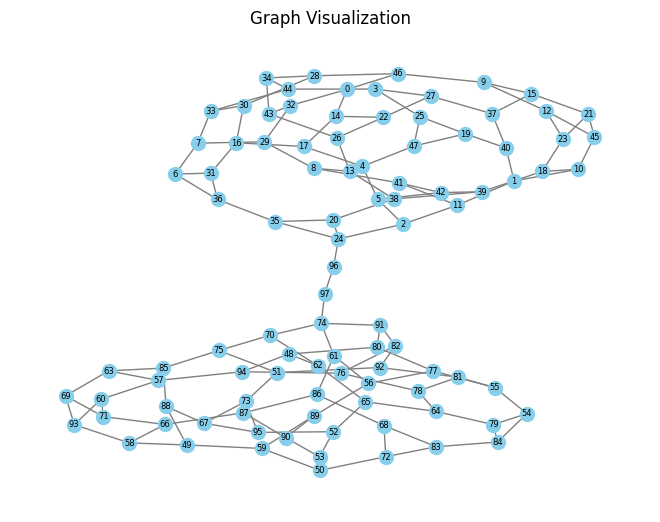

In [2]:
draw_graph_custom(graph)

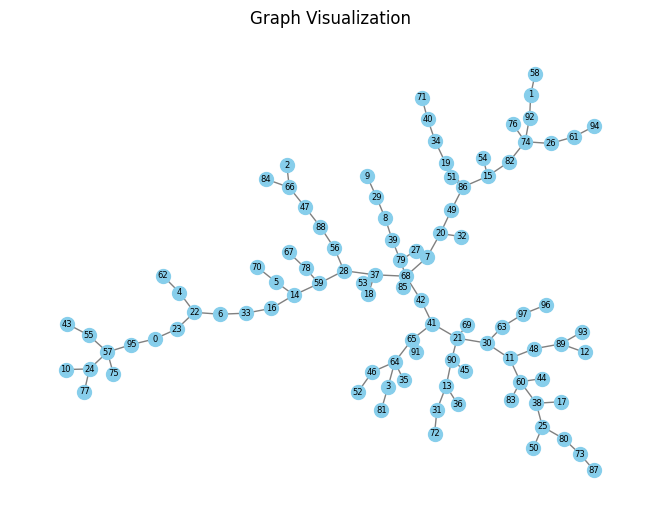

In [3]:
draw_graph_custom(lmao)

In [4]:
lmao.adj[0]

AtlasView({23: {}, 95: {}})

In [6]:
lmao.nodes()

NodeView((78, 59, 25, 50, 1, 58, 2, 66, 60, 83, 74, 82, 0, 23, 96, 97, 42, 41, 13, 90, 18, 37, 88, 56, 30, 11, 20, 49, 86, 15, 5, 14, 46, 52, 3, 81, 28, 21, 33, 6, 51, 68, 79, 19, 34, 92, 39, 73, 87, 48, 22, 43, 55, 10, 24, 80, 38, 63, 69, 32, 8, 29, 53, 72, 31, 35, 64, 26, 61, 27, 57, 75, 16, 44, 54, 94, 62, 4, 47, 89, 12, 70, 95, 65, 67, 85, 17, 7, 36, 76, 40, 93, 9, 91, 71, 77, 45, 84))

In [8]:
adj_matrix = nx.adjacency_matrix(lmao, nodelist=range(lmao.number_of_nodes()))
print(adj_matrix)

<Compressed Sparse Row sparse array of dtype 'int64'
	with 194 stored elements and shape (98, 98)>
  Coords	Values
  (0, 23)	1
  (0, 95)	1
  (1, 58)	1
  (1, 92)	1
  (2, 66)	1
  (3, 64)	1
  (3, 81)	1
  (4, 22)	1
  (4, 62)	1
  (5, 14)	1
  (5, 70)	1
  (6, 22)	1
  (6, 33)	1
  (7, 20)	1
  (7, 68)	1
  (8, 29)	1
  (8, 39)	1
  (9, 29)	1
  (10, 24)	1
  (11, 30)	1
  (11, 48)	1
  (11, 60)	1
  (12, 89)	1
  (13, 31)	1
  (13, 36)	1
  :	:
  (84, 66)	1
  (85, 68)	1
  (86, 15)	1
  (86, 19)	1
  (86, 49)	1
  (86, 51)	1
  (87, 73)	1
  (88, 47)	1
  (88, 56)	1
  (89, 12)	1
  (89, 48)	1
  (89, 93)	1
  (90, 13)	1
  (90, 21)	1
  (90, 45)	1
  (91, 65)	1
  (92, 1)	1
  (92, 74)	1
  (93, 89)	1
  (94, 61)	1
  (95, 0)	1
  (95, 57)	1
  (96, 97)	1
  (97, 63)	1
  (97, 96)	1
